In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import numpy as np

mpl.rcParams['font.sans-serif'] = ['SimHei'] # 设置中文字体为黑体
mpl.rcParams['axes.unicode_minus'] = False # 确保正常显示负号

In [2]:
# 查看Seaborn内置数据集
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [3]:
# 长格式数据
flights = sns.load_dataset("flights")
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [4]:
# 长格式转宽格式数据
flights_wide = flights.pivot(index="year", columns="month", values="passengers")
flights_wide.head()

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
1949,112,118,132,129,121,135,148,148,136,119,104,118
1950,115,126,141,135,125,149,170,170,158,133,114,140
1951,145,150,178,163,172,178,199,199,184,162,146,166
1952,171,180,193,181,183,218,230,242,209,191,172,194
1953,196,196,236,235,229,243,264,272,237,211,180,201


In [5]:
# 宽格式转长格式数据
flights_wide.melt(value_vars=flights_wide.columns.values,value_name='passsengers',ignore_index=False)

,month,passsengers
year,,
1949,Jan,112
1950,Jan,115
1951,Jan,145
1952,Jan,171
1953,Jan,196
...,...,...
1956,Dec,306
1957,Dec,336
1958,Dec,337


## 1. Seaborn绘图设置
### 1.1 Seaborn的五种绘图风格
- darkgrid (default)
- whitegrid
- dark
- white
- ticks

<Axes: >

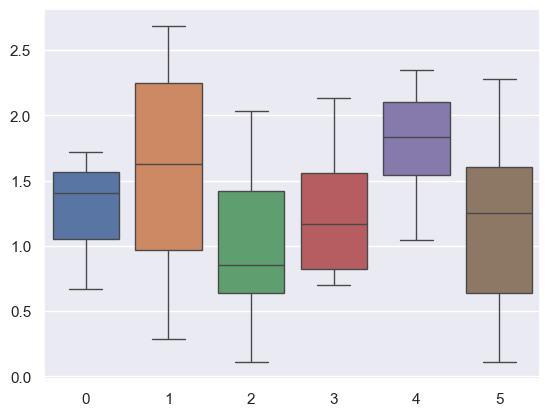

In [2]:
# 生成一组数据
data = [[1.716938, 0.969111, 1.313401, 1.500519, 1.591406, 0.670162],
        [0.288208, 1.031337, 2.683332, 2.227474, 0.947037, 2.257658],
        [1.023312, 0.111484, 0.624475, 0.682342, 1.551981, 2.029264],
        [0.701567, 0.807321, 0.866991, 1.592059, 1.461618, 2.131652],
        [1.766493, 1.469235, 1.045779, 1.899585, 2.344627, 2.173643],
        [0.110403, 0.523769, 0.985059, 1.524016, 1.635007, 2.279868]]

sns.set_theme() # 使用默认主题 (darkgrid),等价于 sns.set_style("darkgrid")
sns.boxplot(data=data)

<Axes: >

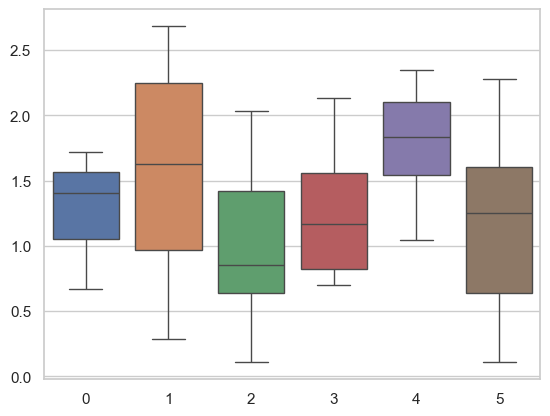

In [7]:
sns.set_style("whitegrid") # 白色网格，默认有边框
sns.boxplot(data=data)
# sns.despine() # despine函数会默认删除上方和右方的边框

<Axes: >

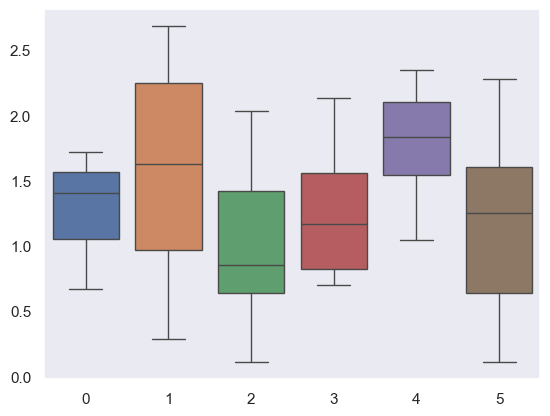

In [8]:
sns.set_style("dark") # 深色背景,无网格
sns.boxplot(data=data)

<Axes: >

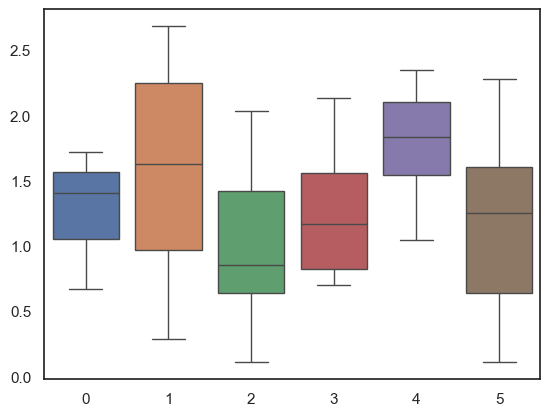

In [9]:
sns.set_style("white") # 白色背景,无网格,默认有边框
sns.boxplot(data=data)
sns.despine()  # 默认删除上方和右方的边框;再手动设置参数删除左边边框

<Axes: >

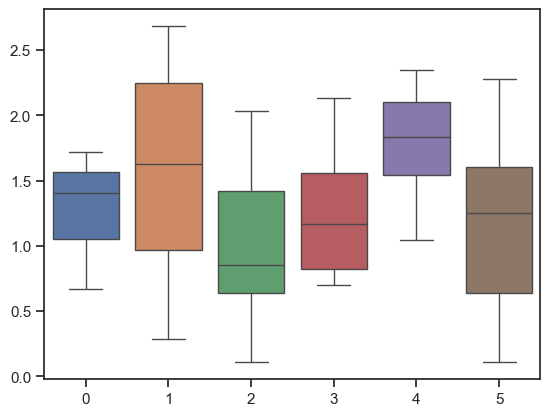

In [10]:
sns.set_style("ticks") # 白色背景,带刻度线
sns.boxplot(data=data)
# sns.despine(left=True)  # 默认删除上方和右方的边框;再手动设置参数删除左边边框

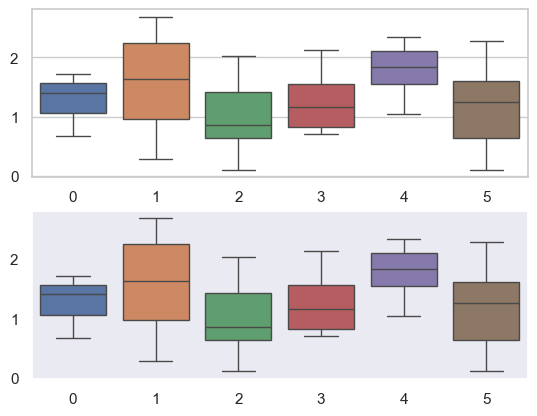

In [11]:
# 两个子图设置不同的风格
fig = plt.figure()
sns.set_style("whitegrid")
plt.subplot(211)
sns.boxplot(data=data)

sns.set_style("dark")
plt.subplot(212)
sns.boxplot(data=data)

plt.show()

In [12]:
#  查看当前子图对象的详细样式设置
sns.axes_style()

{'axes.facecolor': '#EAEAF2',
 'axes.edgecolor': 'white',
 'axes.grid': False,
 'axes.axisbelow': True,
 'axes.labelcolor': '.15',
 'figure.facecolor': 'white',
 'grid.color': 'white',
 'grid.linestyle': '-',
 'text.color': '.15',
 'xtick.color': '.15',
 'ytick.color': '.15',
 'xtick.direction': 'out',
 'ytick.direction': 'out',
 'lines.solid_capstyle': <CapStyle.round: 'round'>,
 'patch.edgecolor': 'w',
 'patch.force_edgecolor': True,
 'image.cmap': 'rocket',
 'font.family': ['sans-serif'],
 'font.sans-serif': ['Arial',
  'DejaVu Sans',
  'Liberation Sans',
  'Bitstream Vera Sans',
  'sans-serif'],
 'xtick.bottom': False,
 'xtick.top': False,
 'ytick.left': False,
 'ytick.right': False,
 'axes.spines.left': True,
 'axes.spines.bottom': True,
 'axes.spines.right': True,
 'axes.spines.top': True}

<Axes: >

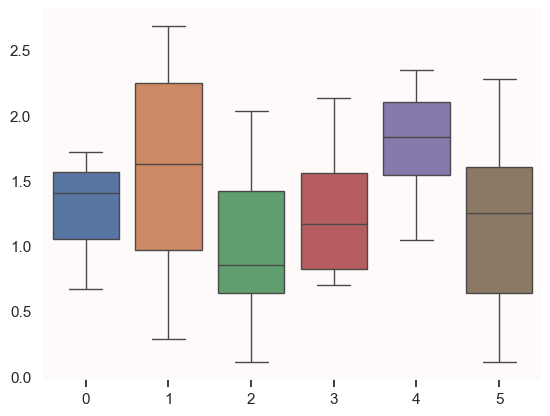

In [13]:
# 使用字典形式修改其中的具体参数设置
sns.set_style("white", rc={"axes.facecolor": '#FFFAFA','axes.edgecolor': '#FFFAFA','xtick.bottom': True})
sns.boxplot(data=data)

### 1.2 Seaborn设置绘图元素缩放比例
#### 内置的四种类型：
- notebook (default)
- paper
- poster
- talk

<Axes: >

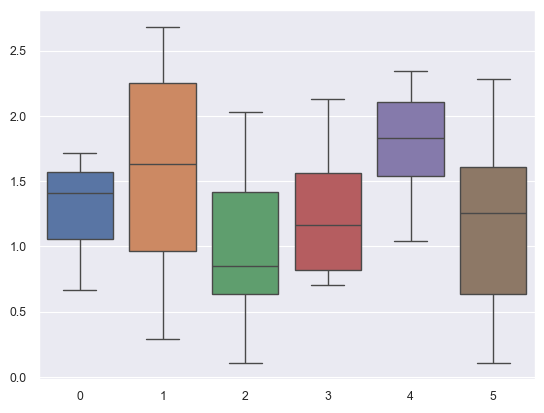

In [14]:
# 激活默认主题设置
sns.set_theme()

sns.set_context("paper") # paper类型
sns.boxplot(data=data)

<Axes: >

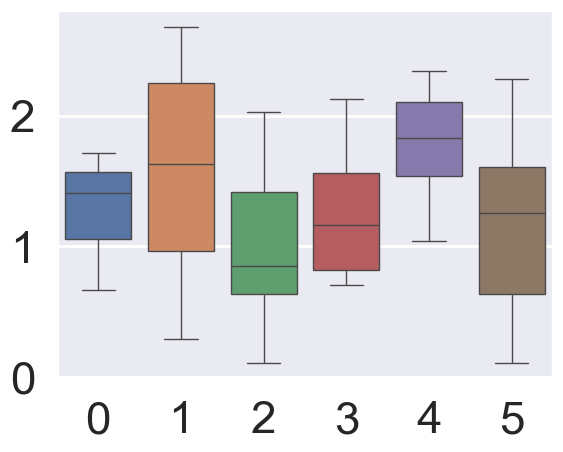

In [15]:
# 使用poster类型,字体缩放比例设置为1.5倍, 线的宽度定义为1.5
sns.set_context("poster", font_scale=1.5, rc={"lines.linewidth": 1.5})
sns.boxplot(data=data)

In [16]:
# 返回控制绘图元素缩放的参数当前值
sns.plotting_context()

{'font.size': 36.0,
 'axes.labelsize': 36.0,
 'axes.titlesize': 36.0,
 'xtick.labelsize': 33.0,
 'ytick.labelsize': 33.0,
 'legend.fontsize': 33.0,
 'legend.title_fontsize': 36.0,
 'axes.linewidth': 2.5,
 'grid.linewidth': 2.0,
 'lines.linewidth': 1.5,
 'lines.markersize': 12.0,
 'patch.linewidth': 2.0,
 'xtick.major.width': 2.5,
 'ytick.major.width': 2.5,
 'xtick.minor.width': 2.0,
 'ytick.minor.width': 2.0,
 'xtick.major.size': 12.0,
 'ytick.major.size': 12.0,
 'xtick.minor.size': 8.0,
 'ytick.minor.size': 8.0}

<Axes: >

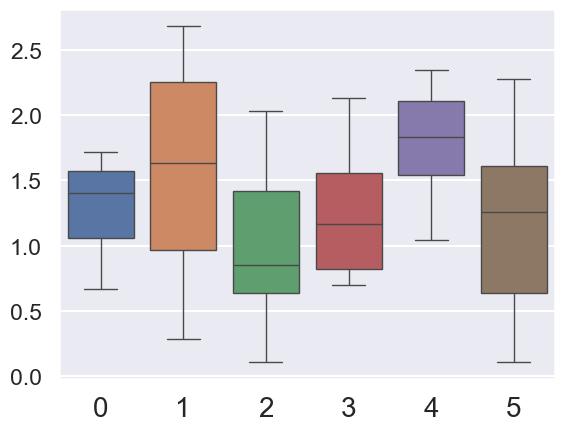

In [17]:
# 以字典形式修改绘图元素缩放参数
sns.set_context("talk", font_scale=1, rc={'xtick.labelsize': 20.0})
sns.boxplot(data=data)

### 1.3 设置绘图的颜色主题
#### 使用sns.set_palette()可以设置调色板
- 分类调色板
- 顺序调色板
- 发散调色板

In [18]:
# 返回当前默认使用的调色板的颜色列表或连续颜色映射
sns.color_palette()

[(0.2980392156862745, 0.4470588235294118, 0.6901960784313725),
 (0.8666666666666667, 0.5176470588235295, 0.3215686274509804),
 (0.3333333333333333, 0.6588235294117647, 0.40784313725490196),
 (0.7686274509803922, 0.3058823529411765, 0.3215686274509804),
 (0.5058823529411764, 0.4470588235294118, 0.7019607843137254),
 (0.5764705882352941, 0.47058823529411764, 0.3764705882352941),
 (0.8549019607843137, 0.5450980392156862, 0.7647058823529411),
 (0.5490196078431373, 0.5490196078431373, 0.5490196078431373),
 (0.8, 0.7254901960784313, 0.4549019607843137),
 (0.39215686274509803, 0.7098039215686275, 0.803921568627451)]

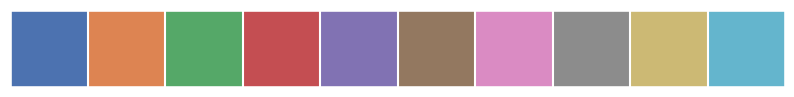

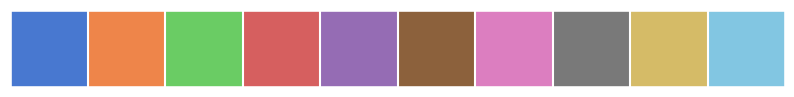

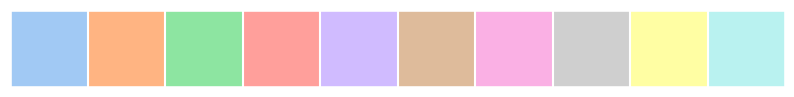

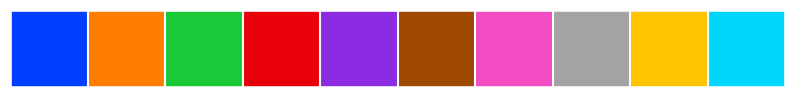

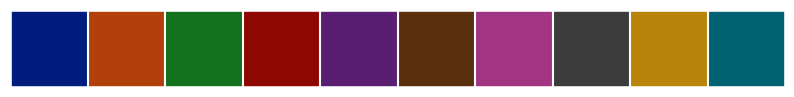

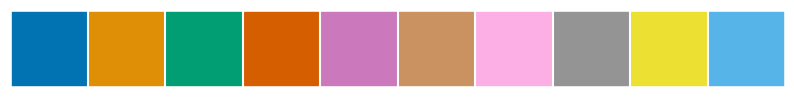

In [19]:
# 分类调色板的五种内置类型
themes = ['deep', 'muted', 'pastel', 'bright', 'dark', 'colorblind']
for theme in themes:
    current_palette = sns.color_palette(theme)
    sns.palplot(current_palette)

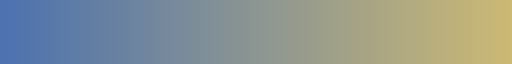

In [4]:
# 顺序调色板, 可以指定‘light:<color>’, ‘dark:<color>’, ‘blend:<color>,<color>’；as_camp=True会返回一个colormap对象
sns.color_palette("blend:b,y", as_cmap=True)

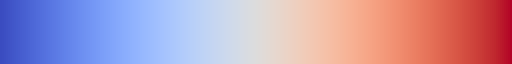

In [5]:
# 发散调色板
sns.color_palette("coolwarm", as_cmap=True) # 'Spectral','coolwarm'

## 2. Seaborn绘图函数：`relplot()` 变量关系图

### 2.1 散点图：sns.relplot(kind='scatter')

In [6]:
# 加载Seaborn内置的示例数据集
tips = sns.load_dataset('tips')
tips.info()
tips.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


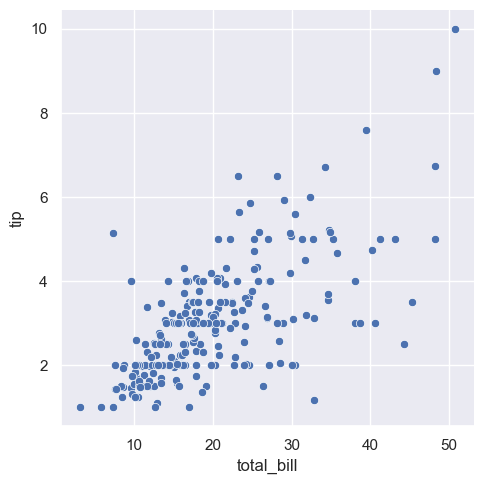

In [7]:
# 绘制账单金额和小费之间的散点图

sns.set_theme() # 使用默认的绘图风格
sns.relplot(data=tips, x="total_bill", y="tip") # 改变图片高度和宽高比

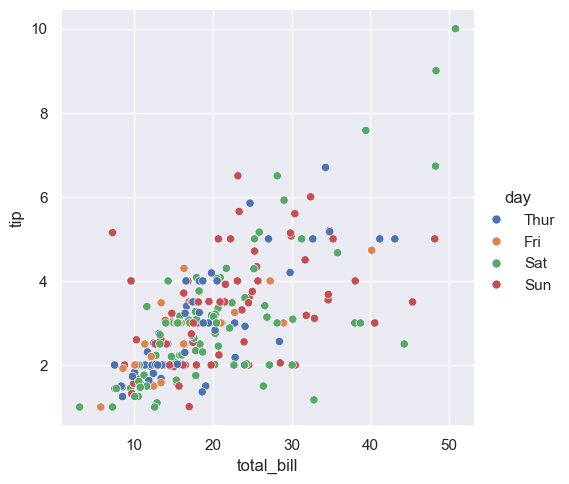

In [8]:
# 按照"day"变量的取值对散点进行分组，用不同颜色呈现
sns.relplot(data=tips, x="total_bill", y="tip", hue="day") # tips['day'].unique()

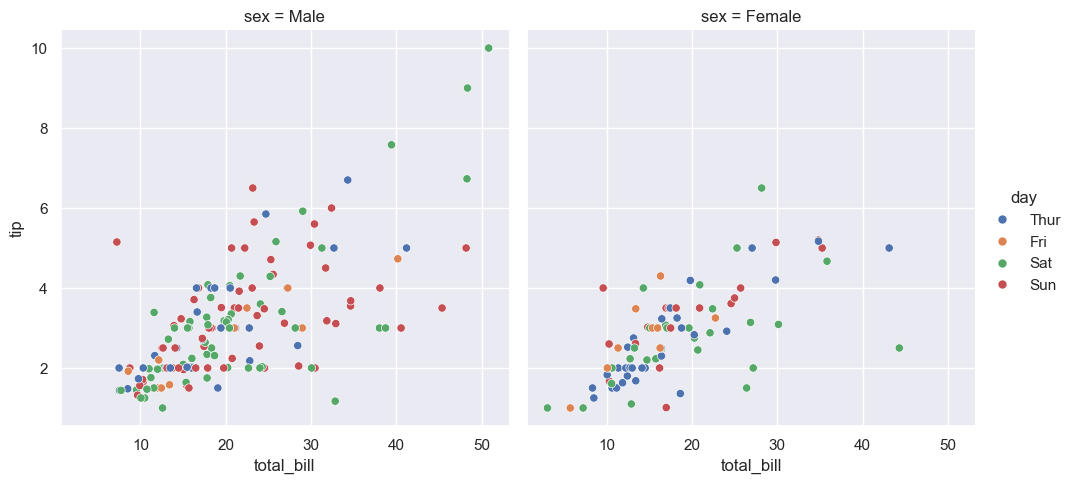

In [9]:
# 进一步按照"sex"变量取值将图形分为两列子图
sns.relplot(data=tips, x="total_bill", y="tip", hue="day", col="sex")

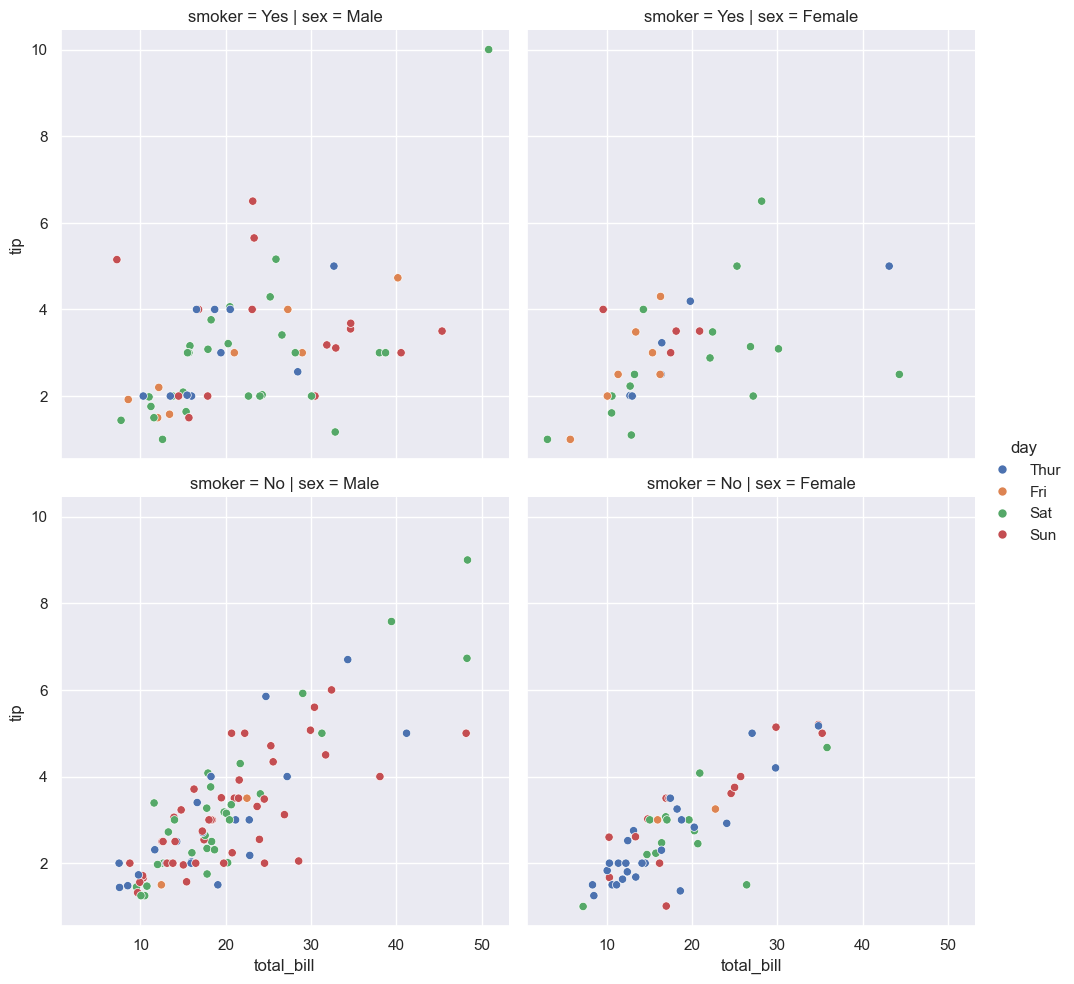

In [26]:
# 按照"sex"、"smoker"(是否吸烟)两个二元变量将图形分为两行两列的子图
sns.relplot(data=tips, x="total_bill", y="tip", hue="day",col="sex", row="smoker")

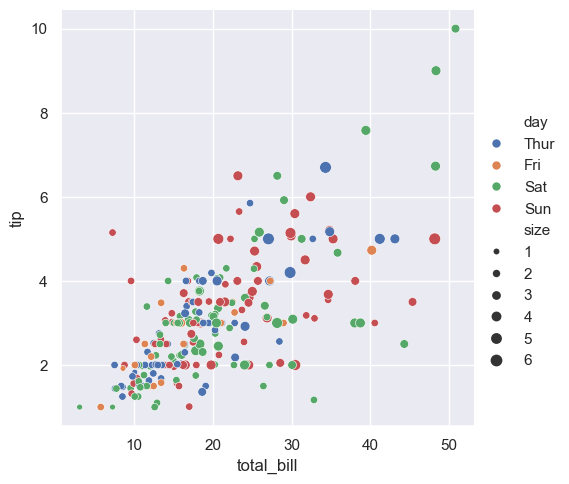

In [27]:
# 按照"size"变量的取值设置散点大小
sns.relplot(data=tips, x="total_bill", y="tip", hue="day", size="size")

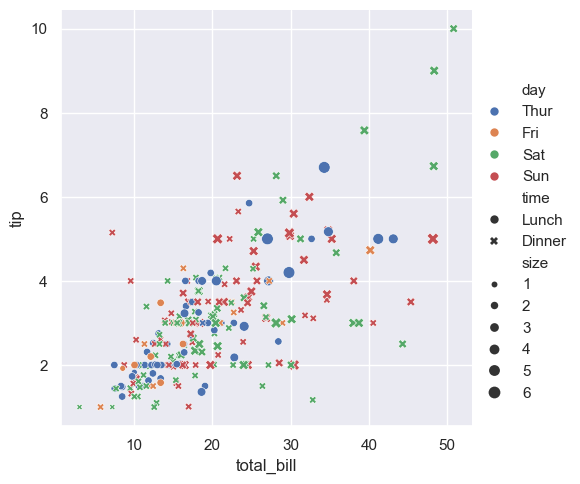

In [28]:
# 进一步按照"time"列的取值设置散点样式
sns.relplot(data=tips, x="total_bill", y="tip", hue="day", size='size', style='time')

### 2.2 线图：sns.relplot(kind='line')

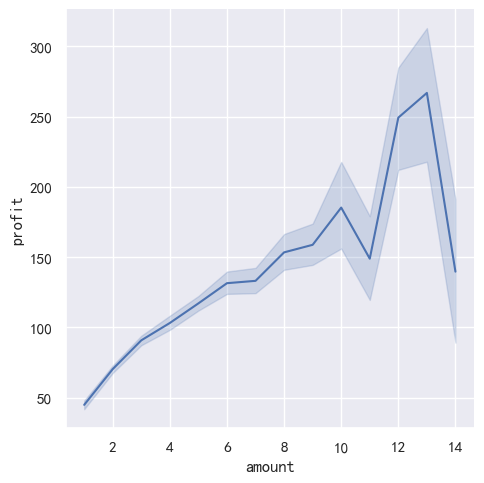

In [29]:
sns.set_theme()
mpl.rcParams['font.sans-serif'] = ['SimHei'] # 设置中文字体为黑体
mpl.rcParams['axes.unicode_minus'] = False # 确保正常显示负号

df = pd.read_table('..\\orders.txt',sep=',')

sns.relplot(data=df, x="amount", y="profit", kind='line')

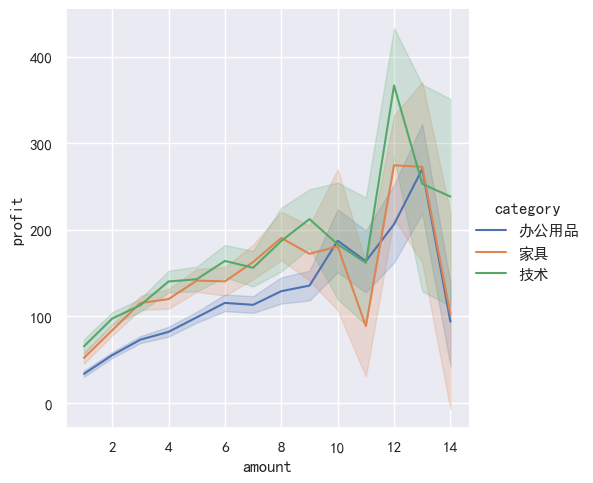

In [30]:
# 根据"category"变量(产品类型)的取值，绘制多条线图，以颜色(hue)区分
sns.relplot(data=df, x="amount", y="profit", kind='line', hue='category')

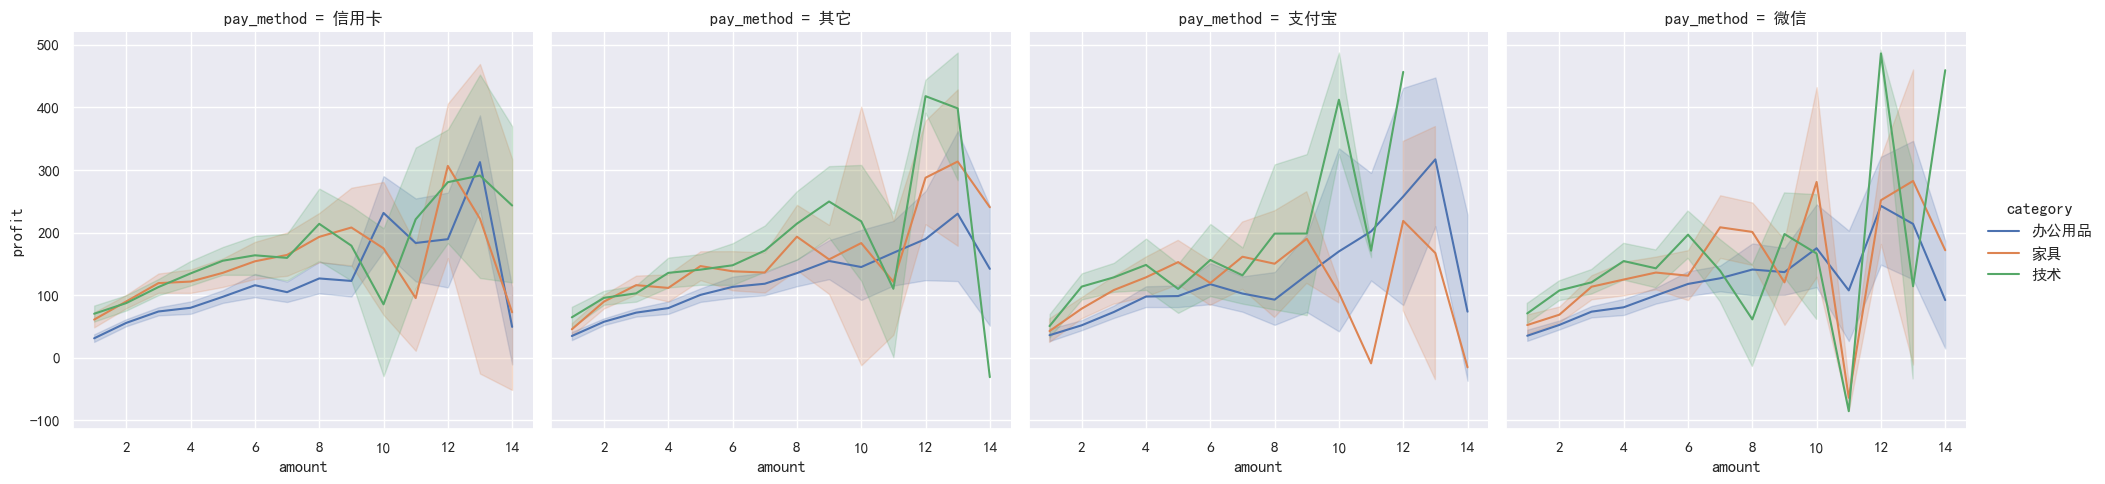

In [31]:
# 根据"pay_method"(支付方法)的类别，在不同列绘制子图
sns.relplot(data=df, x="amount", y="profit", kind='line', hue='category', col='pay_method')

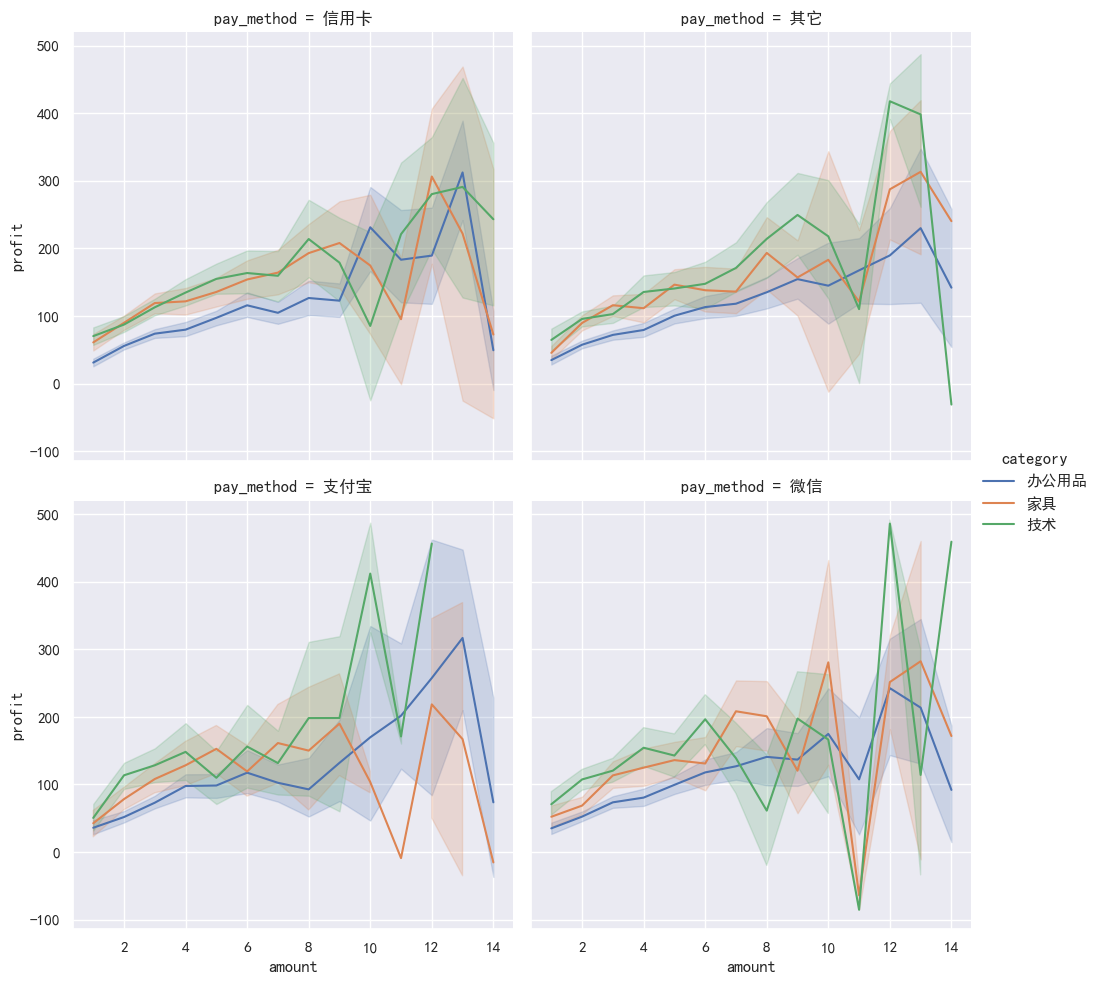

In [32]:
# 设置col_wrap属性，规定列数
sns.relplot(data=df, x="amount", y="profit", kind='line', hue='category', col='pay_method', col_wrap=2)

### 2.3 补充知识: 使用FacetGrid绘图

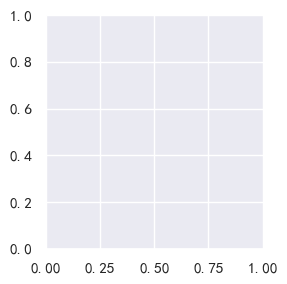

In [33]:
df = pd.read_table('..\\orders.txt',sep=',')

sns.FacetGrid(df) #这里输入的数据是DataFrame，不能是数组

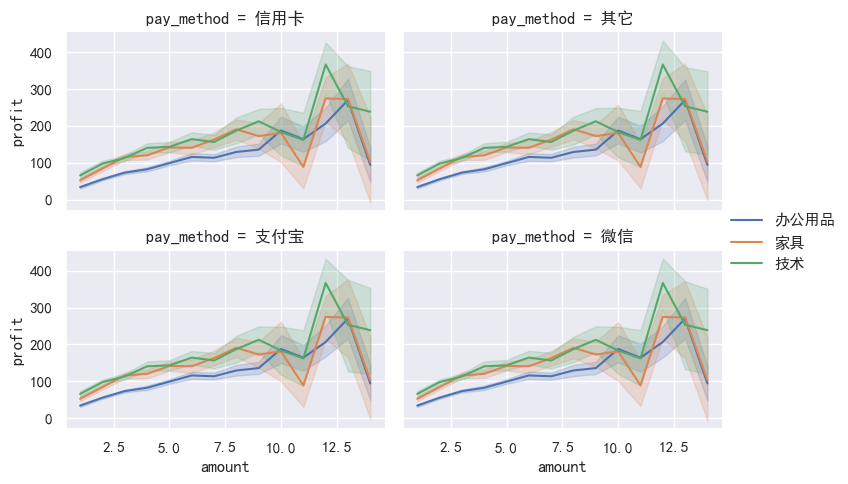

In [34]:
g = sns.FacetGrid(df,col='pay_method', col_wrap=2, height=2.5, aspect=1.5)
# 使用map()方法在FacetGrid的子图上绘制图形
g.map(sns.lineplot, data=df, x='amount', y='profit', hue='category')
g.add_legend()

## 3. Seaborn绘图函数：`displot()` 变量分布图
#### 直方图：sns.displot(kind='hist')
#### 核密度图：sns.displot(kind='kde')
#### 经验累积分布图：sns.displot(kind='ecdf')

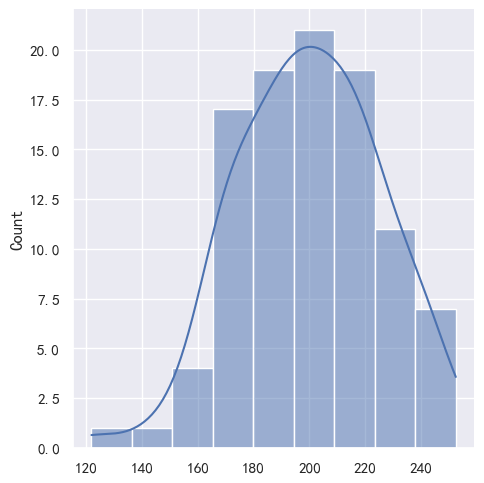

In [35]:
# 设置种子
np.random.seed(19680801)

mu = 200 
sigma = 25
data = np.random.normal(mu, sigma, size=100)

# 绘制直方图
# sns.displot(data,kind='hist')

# 绘制核密度图
# sns.displot(data,kind='kde')

# 绘制经验累积分布图
# sns.displot(data,kind='ecdf')

# 将频数分布和核密度绘制在一条曲线中
sns.displot(data,kde=True)

### 3.1 直方图：sns.displot(kind='hist')或sns.histplot()

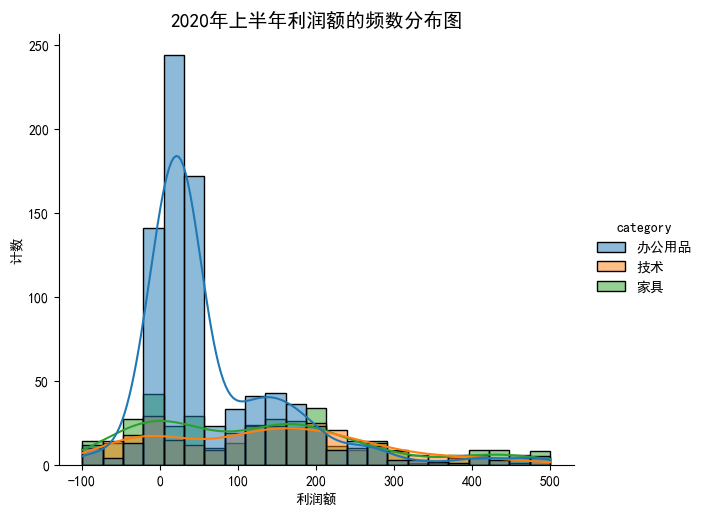

In [3]:
#--------------------(a) sns.displot(kind='hist')----------------------------------------

plt.rcParams['font.sans-serif']=['SimHei'] # 确保正常显示汉字
plt.rcParams['axes.unicode_minus'] = False # 确保正常显示负号

df = pd.read_table('..\\orders.txt',sep=',')
df = df[df['dt']==2020]

# 使用displot绘制频数分布直方图
dist = sns.displot(df, x='profit', kind='hist', hue='category', kde=True, aspect=1.2)
dist.set_xlabels('利润额')
dist.set_ylabels('计数')
plt.title('2020年上半年利润额的频数分布图',fontsize=14)
plt.show()

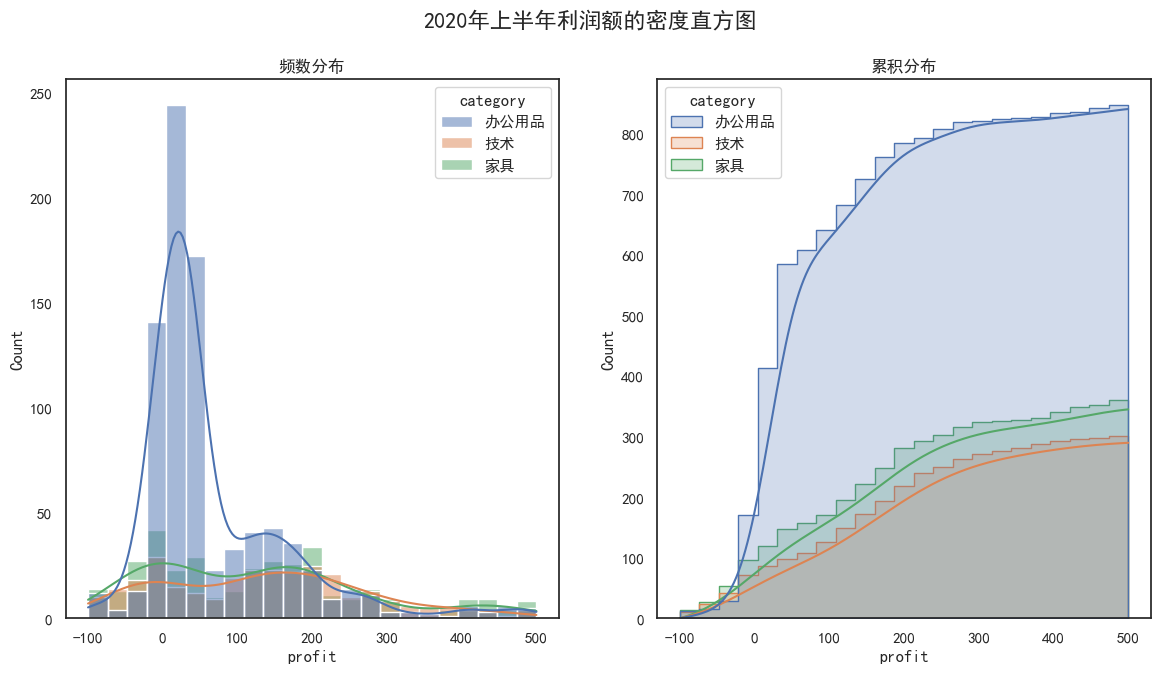

In [37]:
#------------------------------sns.histplot()-----------------------------------------
sns.set_style('white')
mpl.rcParams['font.sans-serif']=['SimHei'] # 确保正常显示汉字
mpl.rcParams['axes.unicode_minus'] = False # 确保正常显示负号

#设置图形大小
plt.figure(figsize=(14,7))

# 子图1：频数分布
ax1 = plt.subplot(121)
sns.histplot(df, x='profit', kde=True, bins='auto', hue='category', ax=ax1)
ax1.set_title("频数分布")

# 子图2：累积分布
ax2 = plt.subplot(122)
sns.histplot(df, x='profit', kde=True, bins='auto', hue='category', cumulative=True, element='step', ax=ax2)
ax2.set_title("累积分布")

plt.suptitle('2020年上半年利润额的密度直方图', size=16)
plt.show()

## 4. Seaborn绘图函数：`catplot()` 分类图
### 4.1 分类散点图：sns.catplot(kind='strip') & sns.catplot(kind='swarm')

In [2]:
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


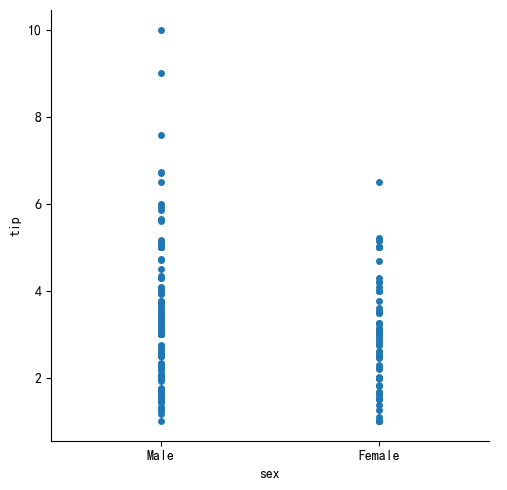

In [3]:
# kind='strip'时，可以设置jitter参数，它控制抖动的幅度，或者完全禁用抖动
sns.catplot(tips, x='sex', y='tip', kind='strip', jitter=False)

E:\Anaconda\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 5.1% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


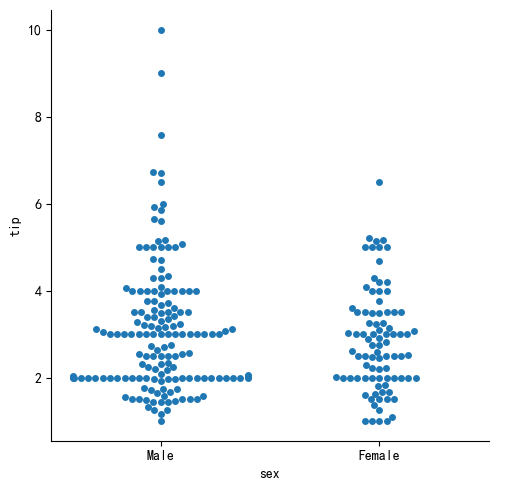

In [4]:
# strip (允许散点重合) vs. swarm ("蜂窝图"，散点不重合，数据量较小时可行)
sns.catplot(tips,x='sex',y='tip',kind='swarm')

### 4.2 分类分布图：箱型图 sns.catplot(kind='box') & 小提琴图 sns.catplot(kind='violin')

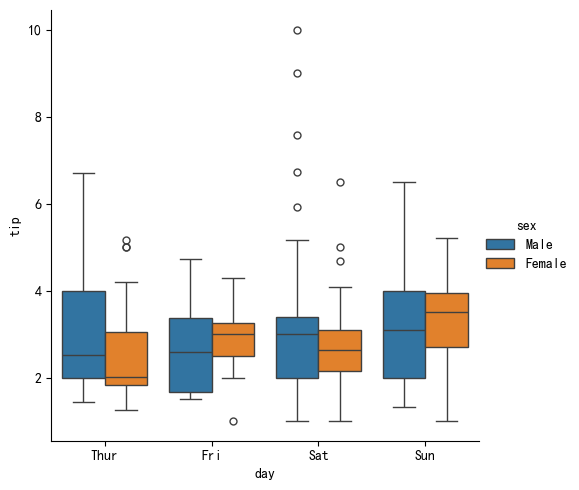

In [12]:
# 绘制箱型图或小提琴图
sns.catplot(tips,x='day',y='tip',hue='sex', kind='box')

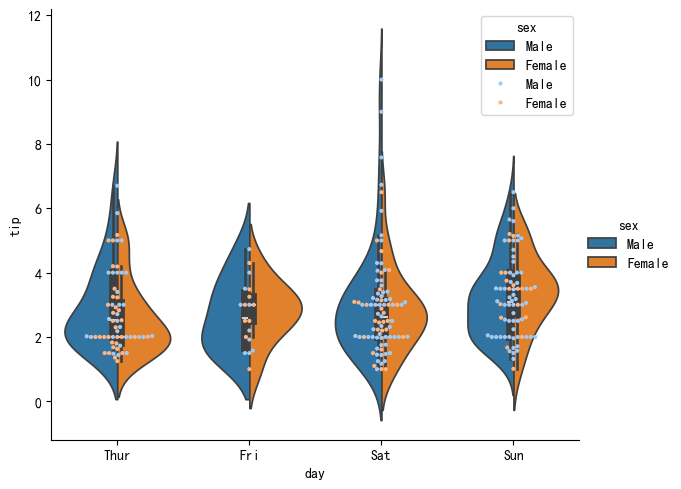

In [8]:
# 在小提琴图上叠加蜂窝散点图(swarmplot())
g = sns.catplot(tips, x="day", y="tip", hue='sex', kind="violin", split=True, aspect=1.2) # split参数指定小提琴内部是否要拆分两个部分
sns.swarmplot(tips, x="day", y="tip", hue='sex', palette='pastel', size=3, ax=g.ax) # ax参数建立对子图的引用
plt.show()

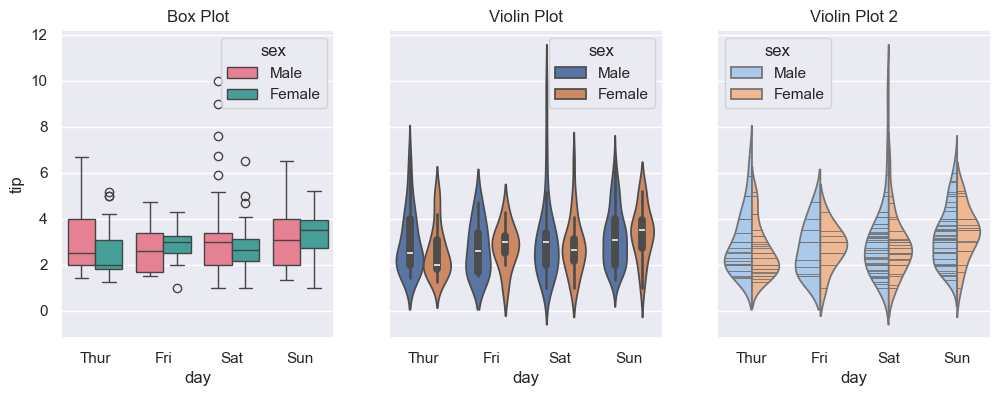

In [15]:
# 在不同子图中绘制箱型图和小提琴图
sns.set_theme()
fig,(ax1,ax2,ax3) = plt.subplots(1,3,figsize=(12,4),sharey=True)

ax1.set_title("Box Plot")
sns.boxplot(tips,x='day',y='tip',hue='sex',ax=ax1, palette='husl') #更改了调色板，使用另一种分类调色板

ax2.set_title("Violin Plot")
sns.violinplot(tips,x='day',y='tip',hue='sex',ax=ax2) # 默认设置的小提琴图

ax3.set_title("Violin Plot 2") # 更改小提琴图的一些图形设置
sns.violinplot(tips,x='day',y='tip',hue='sex',ax=ax3, palette='pastel', inner='stick', split=True)
plt.show()

### 4.3 分类估计图：sns.catplot(kind='bar') & sns.catplot(kind='point')

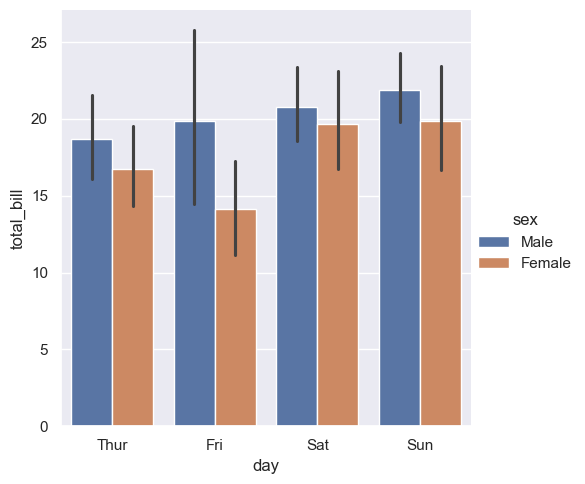

In [16]:
# 绘制带误差估计的条形图：默认情况下，误差线显示95%置信区间
sns.catplot(tips, x='day', y='total_bill', kind='bar', hue='sex')

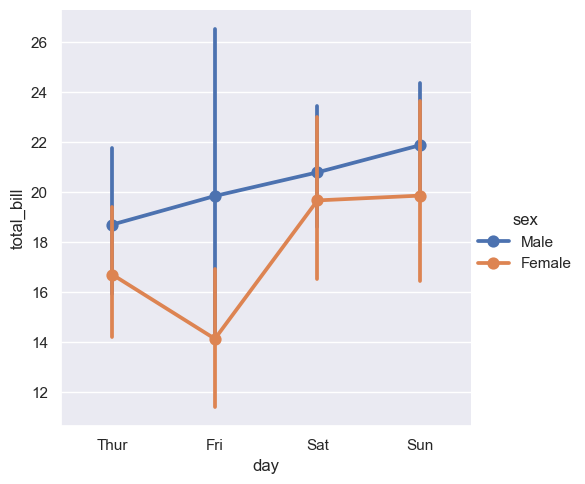

In [17]:
# 绘制点估计图
sns.catplot(tips, x='day', y='total_bill', kind='point', hue='sex')

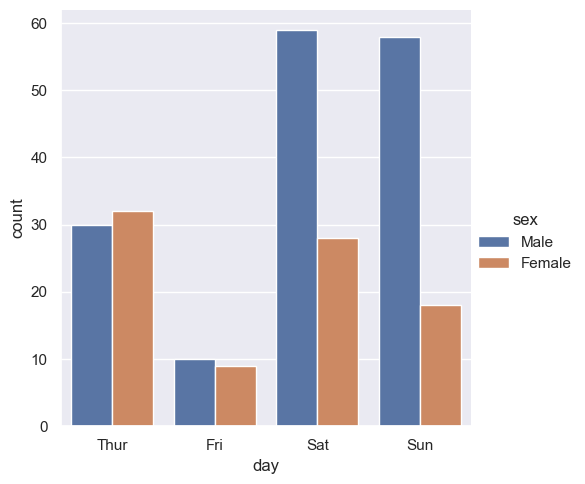

In [18]:
# 绘制计数图
sns.catplot(tips, x='day', kind='count', hue='sex')

## 5. Seaborn绘图函数：`lmplot()` 回归图

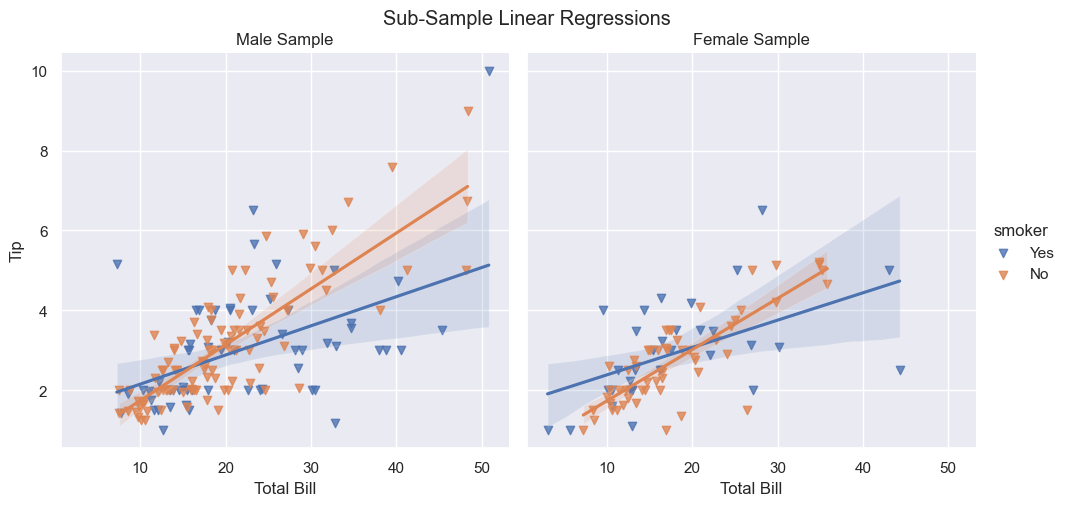

In [21]:
# 绘制账单金额和小费数额之间的线性回归图
g = sns.lmplot(tips,x='total_bill',y='tip',hue='smoker',col='sex', markers='v')

# 修改子图的标题
g.axes_dict['Male'].set_title('Male Sample') # 或者g.axes[0,0].set_title('Male Sample')
g.axes_dict['Female'].set_title('Female Sample') # 或者g.axes[0,1].set_title('Female Sample')

# 修改横轴和纵轴
g.set_xlabels('Total Bill')
g.set_ylabels('Tip')

# 设置图标题
plt.suptitle('Sub-Sample Linear Regressions',y=1.01)

# 保存图片
plt.savefig('tip_reg.png',format='png',bbox_inches='tight')
plt.show()

## 6. Seaborn绘图函数：`pairplot()` & `jointplot()` 
### 统计分布组合图——可视化变量对之间的关系

### 6.1 pairplot()绘制成对（连续）变量的矩阵散点图

In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

sns.set_style("darkgrid",{'axes.facecolor': '.95'})

sns.set_context("notebook", font_scale=1.5,
                rc={'axes.labelsize': 13, 'legend.fontsize':13, 
                    'xtick.labelsize': 12,'ytick.labelsize': 12})

# 导入seaborn自带的鸢尾花数据集
df = sns.load_dataset("iris")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


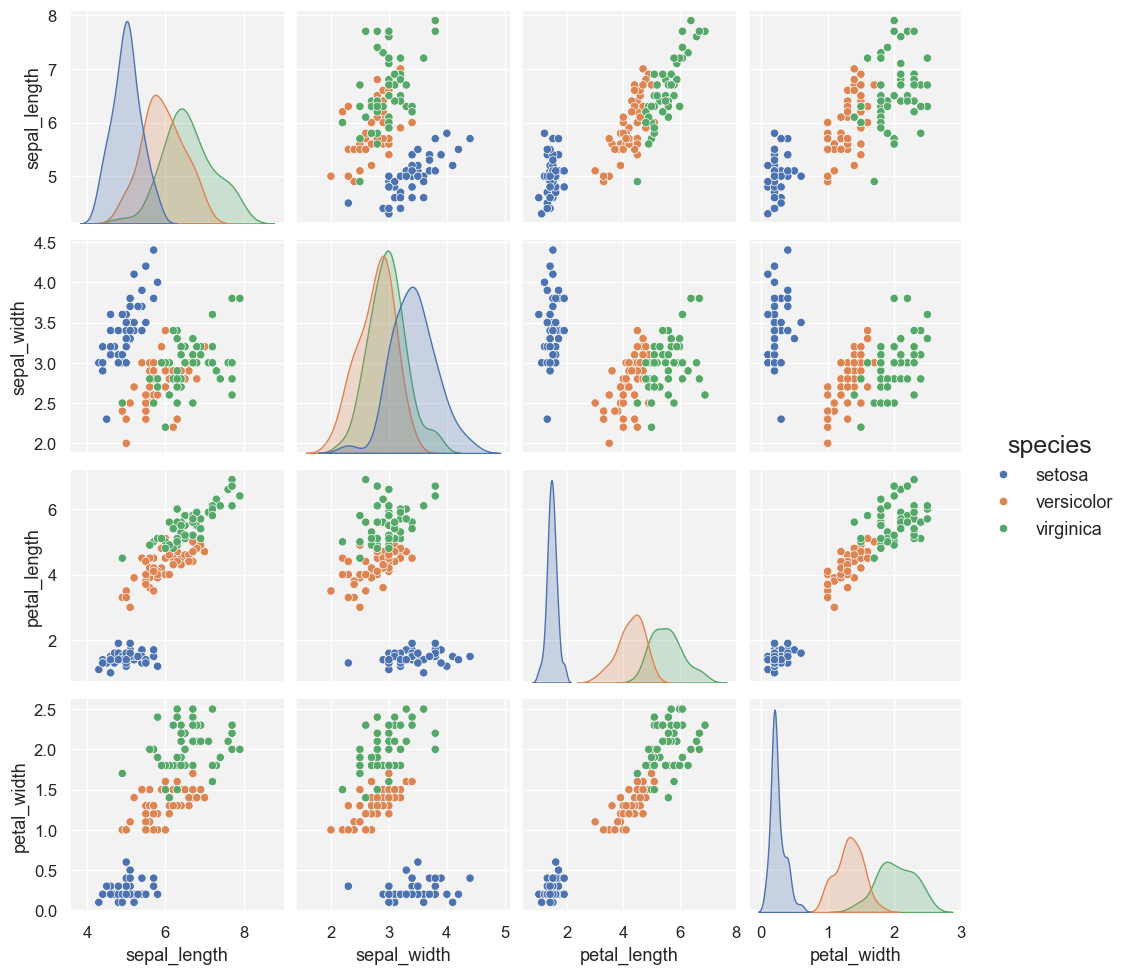

In [24]:
# 参数diag_kind设置对角线上的图表类型，可以更改为'hist'(直方图)，默认为核密度图('kde')

g = sns.pairplot(df, hue='species', kind='scatter', diag_kind='auto') 
g.savefig('pairplot.png',format='png')

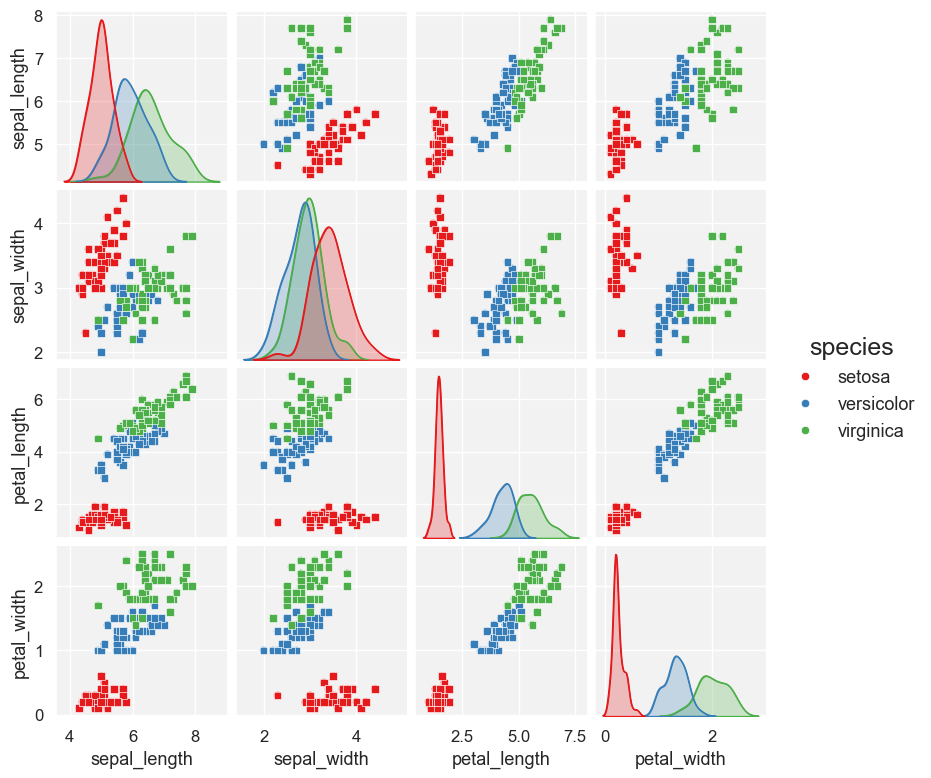

In [50]:
# 方式二：创建一个PairGrid对象，建立对角线图形和非对角线图形的映射

g = sns.pairplot(df, hue="species", height =2, palette ='Set1')

g = g.map_diag(sns.kdeplot, lw=1) # 对角线图形为核密度曲线
g = g.map_offdiag(sns.scatterplot, edgecolor='w', s=30, marker='s') # 非对角线图形为散点图

plt.subplots_adjust(hspace=0.05, wspace=0.05) # 调整各个子图之间的间距
plt.show()

### 6.2 jointplot()绘制成对变量的关系和分布图

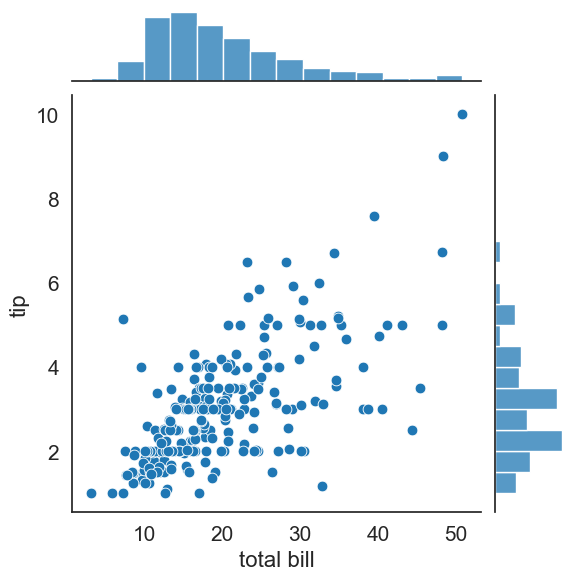

In [9]:
tips = sns.load_dataset("tips")
df=pd.DataFrame({'x':tips['total_bill'],'y':tips['tip']})

sns.set_style("white")
sns.set_context("notebook", font_scale=1.5,
                rc={'font.size': 13, 
                    'axes.labelsize': 16, 'legend.fontsize':16, 
                    'xtick.labelsize': 15,'ytick.labelsize': 15})

#---------------------------------(a) 二维散点与统计直方图 --------------------------------
sns_hist=sns.jointplot(df, x='x', y='y',  # 设置x、y轴要显示的数据
              s = 60, # 设置散点大小(只针对scatter)
              kind = 'scatter') # kind="kde","hex","reg"

sns_hist.set_axis_labels(xlabel='total bill', ylabel='tip') # 设置坐标轴名称


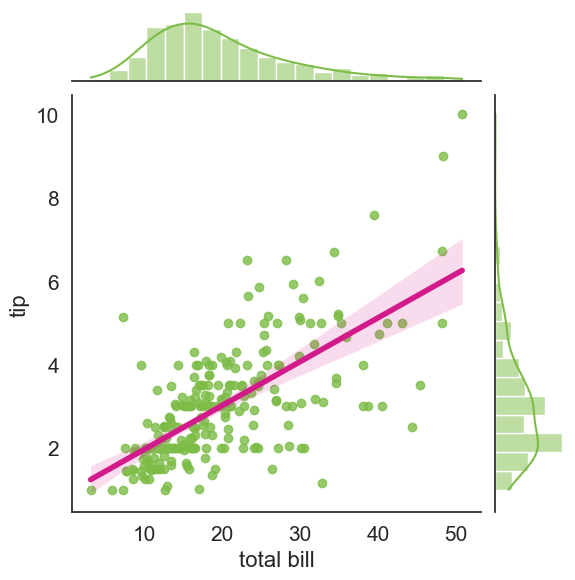

In [52]:
#---------------------------------(b) 带趋势线的二维散点与统计直方图----------------------------------------------------
sns_reg=sns.jointplot(data=df, x='x', y='y',
              color = '#7CBC47',   # 设置颜色
              kind = 'reg', # kind="kde","hex","reg"
              line_kws={"color":"#D31A8A","alpha":1,"lw":4}, # 设置线的颜色、透明度、宽度
              marginal_kws=dict(bins=20, kde=True)  # 设置分箱数
              )

sns_reg.set_axis_labels(xlabel='total bill', ylabel='tip')
plt.show()

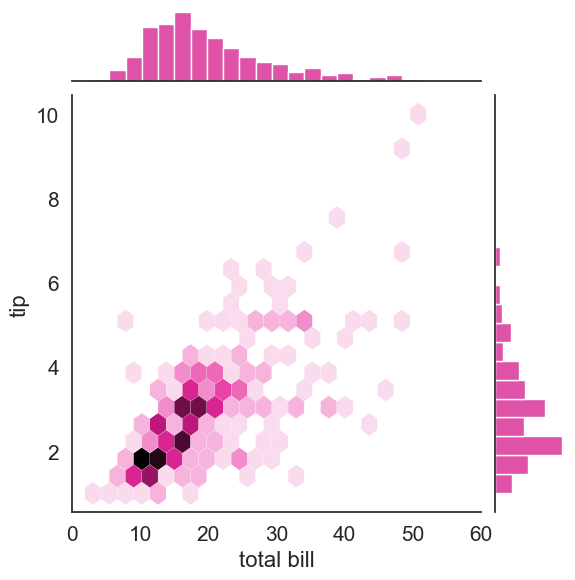

In [29]:
#----------------------------------(c) 二维与一维统计直方图---------------------------------------------------
sns_hex =sns.jointplot(data=df, x='x', y='y',  # 设置x、y轴，显示columns名称
              kind = 'hex', #kind="kde","hex","reg"
              color='#D31A8A', linewidth=0.1,
              xlim=(0,60),
              joint_kws=dict(gridsize=20,edgecolor='w'),  # 主图参数设置
              marginal_kws=dict(bins=20,color='#D31A8A'),   # 边缘图设置
              )  
sns_hex.set_axis_labels(xlabel='total bill', ylabel='tip')

#sns_hex.savefig('sns_hex.pdf')  

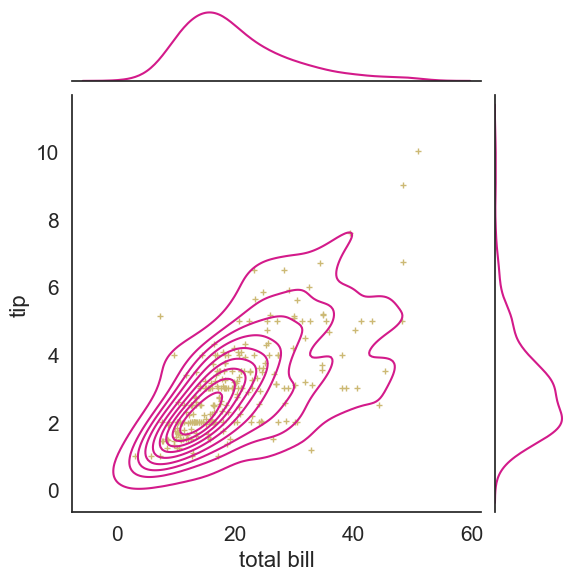

In [54]:
#--------------------------------(d) 二维与一维核密度估计图--------------------------------------------------

sns_kde = sns.jointplot(data=df, x="x", y="y", kind="kde",color='#D31A8A') # 内部绘制联合密度图
sns_kde.plot_joint(plt.scatter, c="y", s=20, linewidth=1, marker="+") # 叠加散点图
sns_kde.set_axis_labels(xlabel='total bill', ylabel='tip') 

## 7. 其他Seaborn绘图案例 

### 带层次聚类的热力图：`sns.clustermap()`

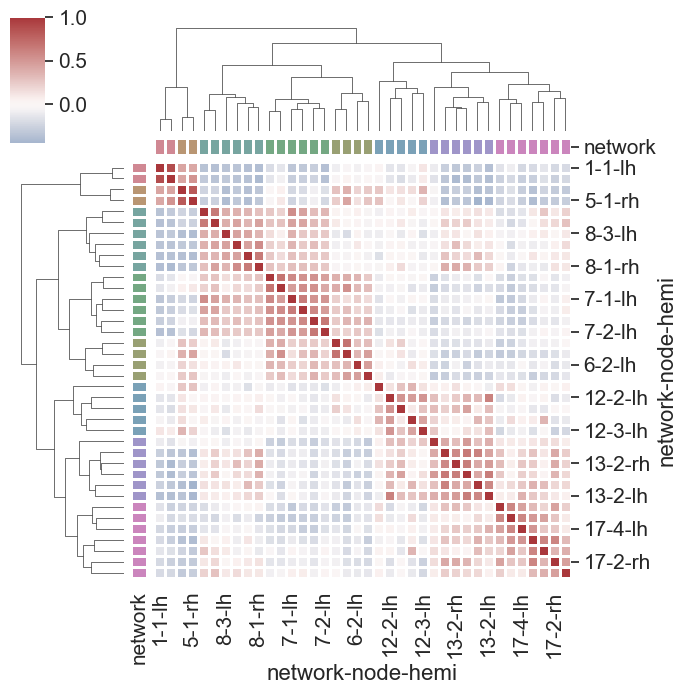

In [55]:
import matplotlib.pyplot as plt 
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import scale

# Load the brain networks example dataset
df = sns.load_dataset("brain_networks", header=[0, 1, 2], index_col=0)
# Select a subset of the networks
used_networks = [1, 5, 6, 7, 8, 12, 13, 17]
used_columns = (df.columns.get_level_values("network")
                          .astype(int)
                          .isin(used_networks))
df = df.loc[:, used_columns]

# Create a categorical palette to identify the networks
network_pal = sns.husl_palette(8, s=.45)
network_lut = dict(zip(map(str, used_networks), network_pal))

# Convert the palette to vectors that will be drawn on the side of the matrix
networks = df.columns.get_level_values("network")
network_colors = pd.Series(networks, index=df.columns).map(network_lut)

# Draw the full plot
sns.clustermap(df.corr(), center=0, cmap="vlag",
               row_colors=network_colors, col_colors=network_colors,
               linewidths=.75, figsize=(7, 7))

plt.show()

### 增强型箱型图：`sns.boxenplot()`

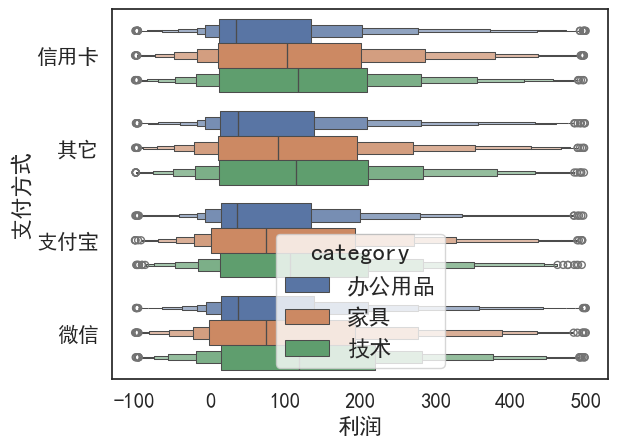

In [56]:
mpl.rcParams['font.sans-serif']=['SimHei'] # 确保正常显示汉字
mpl.rcParams['axes.unicode_minus'] = False # 确保正常显示负号

df = pd.read_table('..\\orders.txt',sep=',')
sns.boxenplot(df,x='profit',y='pay_method', hue='category', legend='auto')
plt.xlabel('利润')
plt.ylabel('支付方式')
plt.show()

### 线性回归
#### 回归图：`sns.regplot()`
#### 残差图：`sns.residplot()`

In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

plt.figure(figsize=[12,7]) # 指定图片大小
sns.set_style('whitegrid') # 设置图形风格为whitegrid
mpl.rcParams['font.sans-serif']=['SimHei'] # 确保正常显示汉字
mpl.rcParams['axes.unicode_minus'] = False # 确保正常显示负号

df = pd.read_table('..\\orders.txt',sep=',')

# x: 2020年各省份产品销售数量
# y: 2020年各省份利润额

x = df[df.dt==2020].groupby(['province'])['amount'].sum()
y = df[df.dt==2020].groupby(['province'])['profit'].sum()
data= pd.concat([x,y],axis=1)
data.head()

,amount,profit
province,,
上海,143,3272.48
云南,85,1858.85
内蒙古,179,4588.09
北京,271,6275.40
吉林,350,8910.42


<Figure size 1200x700 with 0 Axes>

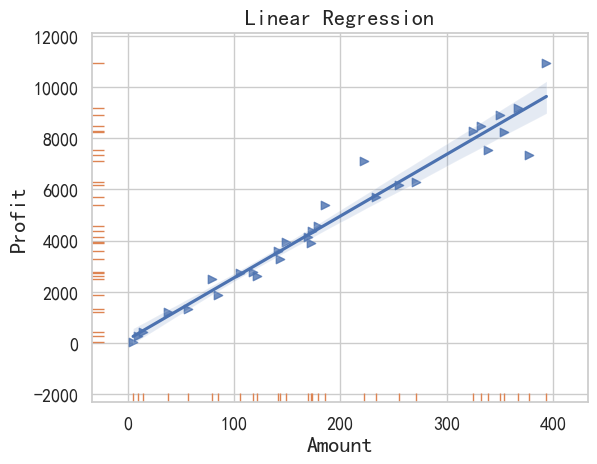

In [58]:
# ----------------------- 线性回归拟合 -------------------------

#设置x轴和y轴的标签大小
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
sns.regplot(data=data, x='amount', y='profit', marker='>')
sns.rugplot(data=data, x='amount', y='profit') # 在坐标轴上显示变量的分布

#给x轴和y轴加上标签
plt.xlabel('Amount',size=16)
plt.ylabel('Profit',size=16)
plt.title('Linear Regression',fontsize=16)
plt.show()

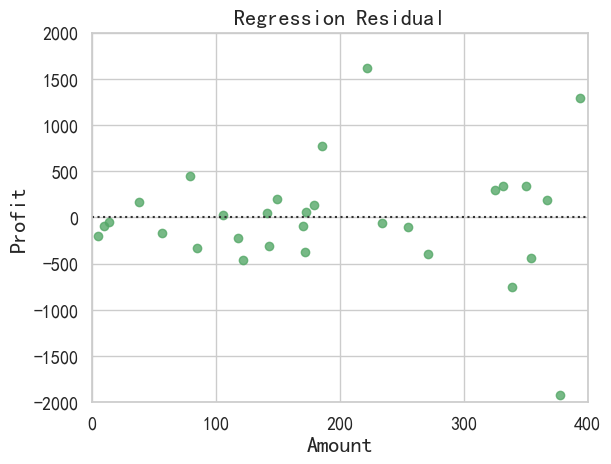

In [59]:
# ----------------------- 线性回归残差-------------------------

#设置x轴和y轴的标签大小
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

#设置x轴和y轴的刻度
plt.xlim(0,400)
plt.ylim(-2000,2000)

#绘制线性回归残差图
sns.residplot(data=data, x='amount', y='profit', color='g')

#给x轴和y轴加上标签
plt.xlabel('Amount',size=16)
plt.ylabel('Profit',size=16)
plt.title('Regression Residual',fontsize=16)
plt.show()